1. Install extra libraries

In [2]:
!pip install shap lime gradio tf_explain dice_ml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 23.0 MB/s eta 0:00:00
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=6dffd64a95ad8cf2f2c1ca2782758821b756c76d0a8358b99c97c30fbcc4033f
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


2. Imports

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_recall_curve,
    average_precision_score,
    roc_curve,
    auc,
    recall_score,
    precision_score,
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay


3. Load data and tidy column names

In [4]:
# 2.1 Load CSV
data_raw = pd.read_csv("/content/drive/MyDrive/coding/Heart disease.csv")

print("Raw shape:", data_raw.shape)
print(data_raw.head())
print(data_raw.columns)

# 2.2 Rename columns to simpler names
data = data_raw.rename(columns={
    'Gender (0: female, 1: male)' : 'Gender',
    'age(years)'                  : 'Age',
    'BMI'                         : 'BMI',
    'ap_hi(Systolic blood pressure)'  : 'SBP',
    'ap_lo(Diastolic blood pressure)' : 'DBP',
    'cholesterol(1: normal, 2: above normal, 3: well above normal)' : 'Cholesterol',
    'Glucose(1: normal, 2: above normal, 3: well above normal)'     : 'Glucose',
    'cardiovascular disease'      : 'CVD_text'
})

# 2.3 Encode target as 0/1
data['CVD'] = (data['CVD_text'] == "has cardiovascular disease").astype(int)

print(data[['CVD_text', 'CVD']].head())
print(data['CVD'].value_counts())


Raw shape: (70000, 11)
   Gender (0: female, 1: male)  age(years)        BMI  \
0                            1          50  21.967120   
1                            0          55  34.927679   
2                            0          52  23.507805   
3                            1          48  28.710479   
4                            0          48  23.011177   

   ap_hi(Systolic blood pressure)  ap_lo(Diastolic blood pressure)  \
0                             110                               80   
1                             140                               90   
2                             130                               70   
3                             150                              100   
4                             100                               60   

   cholesterol(1: normal, 2: above normal, 3: well above normal)  \
0                                                  1               
1                                                  3               
2        

# 4. Basic data check and recommended cleaning

4.1 Check ranges

In [5]:
print(data[['Age','BMI','SBP','DBP']].describe())

                Age           BMI           SBP           DBP
count  70000.000000  70000.000000  70000.000000  70000.000000
mean      53.338686     27.556513    128.817286     96.630414
std        6.765294      6.091511    154.011419    188.472530
min       30.000000      3.471784   -150.000000    -70.000000
25%       48.000000     23.875115    120.000000     80.000000
50%       54.000000     26.374068    120.000000     80.000000
75%       58.000000     30.222222    140.000000     90.000000
max       65.000000    298.666667  16020.000000  11000.000000


4.2 Clean outliers

In [6]:
# Copy to avoid touching the original
df = data.copy()

# Filter to plausible ranges
df = df[
    (df['BMI'] >= 12) & (df['BMI'] <= 60) &
    (df['SBP'] >= 80) & (df['SBP'] <= 260) &
    (df['DBP'] >= 40) & (df['DBP'] <= 140)
]

# Also enforce SBP > DBP
df = df[df['SBP'] > df['DBP']]

print("After cleaning, shape:", df.shape)
print(df['CVD'].value_counts())

After cleaning, shape: (68592, 12)
CVD
0    34659
1    33933
Name: count, dtype: int64


5. Feature engineering (Pulse Pressure, MAP, risk count)

In [7]:
# 4.1 Pulse pressure and mean arterial pressure
df['PP']  = df['SBP'] - df['DBP']                  # pulse pressure
df['MAP'] = (df['SBP'] + 2*df['DBP']) / 3.0       # mean arterial pressure

# 4.2 Simple risk-factor count
# risk_factor_count = high cholesterol + high glucose + smoking + alcohol + inactivity
df['risk_count'] = (
    (df['Cholesterol'] > 1).astype(int) +
    (df['Glucose'] > 1).astype(int) +
    df['smoking'] +
    df['alcohol'] +
    (1 - df['active'])
)

df[['PP','MAP','risk_count']].describe()


,PP,MAP,risk_count
count,68592.000000,68592.000000,68592.000000
mean,45.367740,96.422455,0.737841
std,11.659327,11.018797,0.878848
min,5.000000,53.333333,0.000000
25%,40.000000,93.333333,0.000000
50%,40.000000,93.333333,1.000000
75%,50.000000,103.333333,1.000000
max,140.000000,173.333333,5.000000


6. Final feature list (base + engineered)

In [8]:
base_features = [
    "Gender", "Age", "BMI", "SBP", "DBP",
    "Cholesterol", "Glucose", "smoking", "alcohol", "active"
]
engineered_features = ["PP", "MAP", "risk_count"]

feature_cols = base_features + engineered_features   # total 13 features
target_col   = "CVD"

X = df[feature_cols].copy()
y = df[target_col].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("y distribution:\n", y.value_counts())


X shape: (68592, 13)
y shape: (68592,)
y distribution:
 CVD
0    34659
1    33933
Name: count, dtype: int64


7. Correlation heatmap (EDA)

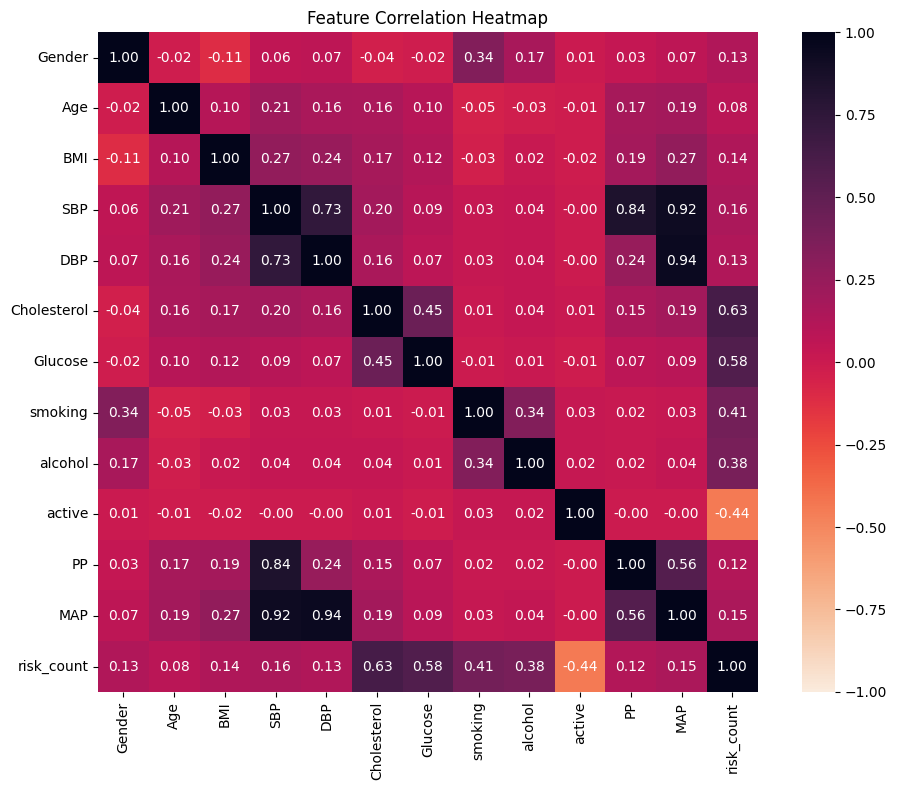

In [9]:
corr = X.corr()

rocket_cmap = sns.color_palette("rocket", as_cmap=True).reversed()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap=rocket_cmap,
    vmin=-1, vmax=1,
    square=True
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

8. Train / validation / test split (70% / 15% / 15%)

In [10]:
# First: 15% test, 85% temp
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

# Then: from the remaining 85%, split into 70% train and 15% validation
# 0.15 / 0.85 ≈ 0.1765
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1765,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

Train: (48012, 13)
Val  : (10291, 13)
Test : (10289, 13)


8.1 Helper function to evaluate any model

In [11]:
def eval_on_val_and_test(name, fitted_model,
                         X_val, y_val,
                         X_test, y_test):
    """Return a dict of metrics for a fitted classifier."""
    y_val_proba  = fitted_model.predict_proba(X_val)[:, 1]
    y_val_pred   = fitted_model.predict(X_val)

    y_test_proba = fitted_model.predict_proba(X_test)[:, 1]
    y_test_pred  = fitted_model.predict(X_test)

    return {
        "Model": name,
        "Val AUC":  roc_auc_score(y_val,  y_val_proba),
        "Val acc":  accuracy_score(y_val,  y_val_pred),
        "Val F1":   f1_score(y_val,  y_val_pred),
        "Test AUC": roc_auc_score(y_test, y_test_proba),
        "Test acc": accuracy_score(y_test, y_test_pred),
        "Test F1":  f1_score(y_test, y_test_pred),
    }

8.2 Logistic Regression baseline

In [12]:
# ===== Logistic Regression (baseline) =====
log_reg_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        max_iter=1000,
        n_jobs=-1
    ))
])

log_reg_param_dist = {
    "clf__C": np.logspace(-2, 1, 6),   # 0.01 ... 10
    "clf__penalty": ["l2"],
    "clf__solver": ["lbfgs"],
}

log_reg_search = RandomizedSearchCV(
    log_reg_pipe,
    param_distributions=log_reg_param_dist,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

print("Fitting Logistic Regression...")
log_reg_search.fit(X_train, y_train)
log_reg_best = log_reg_search.best_estimator_
print("Best LR params:", log_reg_search.best_params_)

lr_metrics = eval_on_val_and_test(
    "Logistic Regression",
    log_reg_best,
    X_val, y_val,
    X_test, y_test
)
print(lr_metrics)

Fitting Logistic Regression...
Fitting 3 folds for each of 6 candidates, totalling 18 fits


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 6 is smaller than n_iter=10. Running 6 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best LR params: {'clf__solver': 'lbfgs', 'clf__penalty': 'l2', 'clf__C': np.float64(0.01)}
{'Model': 'Logistic Regression', 'Val AUC': np.float64(0.7976028587401598), 'Val acc': 0.7316101447867068, 'Val F1': 0.7111482953357038, 'Test AUC': np.float64(0.7894511223444436), 'Test acc': 0.7271843716590534, 'Test F1': 0.7053018372703412}


8.3 Random Forest baseline

In [13]:
# ===== Random Forest (baseline) =====
rf_pipe = Pipeline([
    ("scaler", StandardScaler()),  # not strictly needed but harmless
    ("clf", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_param_dist = {
    "clf__n_estimators": [200, 300, 400],
    "clf__max_depth": [None, 8, 16, 32],
    "clf__min_samples_split": [2, 5, 10],
    "clf__max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    rf_pipe,
    param_distributions=rf_param_dist,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

print("Fitting Random Forest...")
rf_search.fit(X_train, y_train)
rf_best = rf_search.best_estimator_
print("Best RF params:", rf_search.best_params_)

rf_metrics = eval_on_val_and_test(
    "Random Forest",
    rf_best,
    X_val, y_val,
    X_test, y_test
)
print(rf_metrics)

Fitting Random Forest...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best RF params: {'clf__n_estimators': 300, 'clf__min_samples_split': 10, 'clf__max_features': 'log2', 'clf__max_depth': 8}
{'Model': 'Random Forest', 'Val AUC': np.float64(0.8047034170406298), 'Val acc': 0.7329705567972015, 'Val F1': 0.7088366179275271, 'Test AUC': np.float64(0.7966659940271119), 'Test acc': 0.7348624744873166, 'Test F1': 0.7108331566673733}


8.4 SVM baseline (RBF kernel)

In [14]:
# ===== SVM with RBF kernel (baseline) =====
svm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(
        kernel="rbf",
        probability=True,   # needed for ROC-AUC
        random_state=42
    ))
])

svm_param_dist = {
    "clf__C": np.logspace(-1, 1, 6),   # 0.1 ... 10
    "clf__gamma": ["scale", "auto", 0.1, 0.01]
}

svm_search = RandomizedSearchCV(
    svm_pipe,
    param_distributions=svm_param_dist,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

print("Fitting SVM (RBF)...")
svm_search.fit(X_train, y_train)
svm_best = svm_search.best_estimator_
print("Best SVM params:", svm_search.best_params_)

svm_metrics = eval_on_val_and_test(
    "SVM (RBF)",
    svm_best,
    X_val, y_val,
    X_test, y_test
)
print(svm_metrics)

Fitting SVM (RBF)...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best SVM params: {'clf__gamma': 0.01, 'clf__C': np.float64(0.6309573444801934)}
{'Model': 'SVM (RBF)', 'Val AUC': np.float64(0.7993815254672649), 'Val acc': 0.7336507628024488, 'Val F1': 0.7091777188328913, 'Test AUC': np.float64(0.7883291746826029), 'Test acc': 0.7298085333851686, 'Test F1': 0.7043182301637949}


9. Hyperparameter-tuned MLP neural network

In [15]:
from sklearn.model_selection import RandomizedSearchCV

base_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        max_iter=500,
        random_state=42
    ))
])

param_dist = {
    "mlp__hidden_layer_sizes": [
        (16, 16),
        (32, 16),
        (32, 32),
        (64, 32)
    ],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": [1e-5, 1e-4, 1e-3],
    "mlp__learning_rate_init": [1e-3, 3e-3, 1e-2],
    "mlp__solver": ["adam"],
}

nn_search = RandomizedSearchCV(
    base_pipe,
    param_distributions=param_dist,
    n_iter=20,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=2
)

print("Fitting hyperparameter search for NN...")
nn_search.fit(X_train, y_train)

print("Best NN params:", nn_search.best_params_)
print("Best CV AUC   :", nn_search.best_score_)

# Final model
model = nn_search.best_estimator_

# Quick validation check (optional)
y_val_proba = model.predict_proba(X_val)[:, 1]
y_val_pred  = model.predict(X_val)
print(f"Validation AUC:  {roc_auc_score(y_val, y_val_proba):.3f}")
print(f"Validation acc:  {accuracy_score(y_val, y_val_pred):.3f}")

Fitting hyperparameter search for NN...
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best NN params: {'mlp__solver': 'adam', 'mlp__learning_rate_init': 0.001, 'mlp__hidden_layer_sizes': (16, 16), 'mlp__alpha': 0.0001, 'mlp__activation': 'relu'}
Best CV AUC   : 0.7963997962226553
Validation AUC:  0.804
Validation acc:  0.738


Make a comparison table (for the paper)

In [16]:
nn_metrics = eval_on_val_and_test(
    "MLP",
    model,
    X_val, y_val,
    X_test, y_test
)

perf_df = pd.DataFrame([
    lr_metrics,
    rf_metrics,
    svm_metrics,
    nn_metrics
]).set_index("Model")

perf_df_rounded = perf_df.round(3)
print(perf_df_rounded)
df.round(3)
print(perf_df_rounded)

                     Val AUC  Val acc  Val F1  Test AUC  Test acc  Test F1
Model                                                                     
Logistic Regression    0.798    0.732   0.711     0.789     0.727    0.705
Random Forest          0.805    0.733   0.709     0.797     0.735    0.711
SVM (RBF)              0.799    0.734   0.709     0.788     0.730    0.704
MLP                    0.804    0.738   0.724     0.797     0.733    0.718
                     Val AUC  Val acc  Val F1  Test AUC  Test acc  Test F1
Model                                                                     
Logistic Regression    0.798    0.732   0.711     0.789     0.727    0.705
Random Forest          0.805    0.733   0.709     0.797     0.735    0.711
SVM (RBF)              0.799    0.734   0.709     0.788     0.730    0.704
MLP                    0.804    0.738   0.724     0.797     0.733    0.718


Integrated Gradients for NN Explanation

In [19]:
!pip install -q tf-explain

In [77]:
import tensorflow as tf
import shap
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler # Ensure StandardScaler is imported

# --- Prepare data and Keras model consistent with the best-performing sklearn pipeline ---
# The best sklearn model (model variable) is a Pipeline: StandardScaler + MLPClassifier
# We need to replicate this preprocessing for the Keras model.

# 1. Get the StandardScaler from the best sklearn pipeline
scaler = model.named_steps['scaler']

# 2. Apply scaling to training and testing data
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Recreate the Keras model architecture from the best MLPClassifier
# Extract hyperparameters from the best MLPClassifier in the pipeline
best_mlp_params = model.named_steps['mlp'].get_params()
hidden_layer_sizes = best_mlp_params['hidden_layer_sizes']
activation = best_mlp_params['activation']

# Define the Keras model
model_keras = tf.keras.Sequential()
model_keras.add(tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)))
for h_size in hidden_layer_sizes:
    model_keras.add(tf.keras.layers.Dense(h_size, activation=activation))
model_keras.add(tf.keras.layers.Dense(2, activation='softmax')) # Output layer for 2 classes

# Compile and train the Keras model on scaled data
model_keras.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_keras.fit(X_train_scaled, y_train, epochs=10, batch_size=32, verbose=0)


# --- Use SHAP's DeepExplainer for Integrated Gradients-like explanation ---

# DeepExplainer requires a background dataset. Using a sample of the scaled training data.
# The number of background samples (100) is a common heuristic.
X_background_deep = shap.sample(X_train_scaled, 100)

# Initialize DeepExplainer with the Keras model and background data
explainer_deep = shap.DeepExplainer(model_keras, X_background_deep)

# Define idx for the example patient to explain locally
idx = 1 # Default index for local explanation

# Compute SHAP values for the chosen test instance
# Ensure idx is a valid index for X_test_scaled
idx_to_explain = idx # Using the same 'idx' from previous local explanation cells
sample_to_explain_scaled = X_test_scaled[idx_to_explain:idx_to_explain+1]

# shap_values_deep will be a list of two arrays for binary classification (one for each class)
shap_values_deep = explainer_deep.shap_values(sample_to_explain_scaled)

# We are interested in the SHAP values for class 1 (CVD)
shap_values_class1 = shap_values_deep[1][0] # [1] for class 1, [0] for the first (and only) sample

# --- Visualize explanation ---
# Bar plot
plt.figure(figsize=(10, 6))
plt.barh(feature_cols, shap_values_class1)
plt.xlabel("SHAP Value (Integrated Gradients-like)")
plt.ylabel("Feature")
plt.title(f"SHAP Values for Example Patient (Class CVD, index {idx_to_explain})")
plt.gca().invert_yaxis() # To have the most important feature at the top
plt.tight_layout()
plt.show()

# Waterfall plot (excellent for individual explanations)
expected_value_class1 = explainer_deep.expected_value[1] # Expected value for class 1
shap.plots.waterfall(shap.Explanation(values=shap_values_class1,
                                     base_values=expected_value_class1,
                                     data=X_test_scaled[idx_to_explain],
                                     feature_names=feature_cols))

/usr/local/lib/python3.12/dist-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_41
Received: inputs=['Tensor(shape=(100, 13))']
  warnings.warn(msg)
/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_41
Received: inputs=['Tensor(shape=(200, 13))']
  warnings.warn(msg)
/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_41
Received: inputs=['Tensor(shape=(1, 13))']
  warnings.

IndexError: index 1 is out of bounds for axis 0 with size 1

10. Final evaluation on test set

In [28]:
y_test_proba = model.predict_proba(X_test)[:, 1]
y_test_pred  = model.predict(X_test)

test_acc = accuracy_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_proba)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test ROC-AUC : {test_auc:.3f}")

print("\nClassification report (test):")
print(classification_report(y_test, y_test_pred, digits=3))

Test accuracy: 0.733
Test ROC-AUC : 0.797

Classification report (test):
              precision    recall  f1-score   support

           0      0.718     0.777     0.746      5199
           1      0.751     0.688     0.718      5090

    accuracy                          0.733     10289
   macro avg      0.735     0.733     0.732     10289
weighted avg      0.734     0.733     0.732     10289



Confusion matrices (train + test)

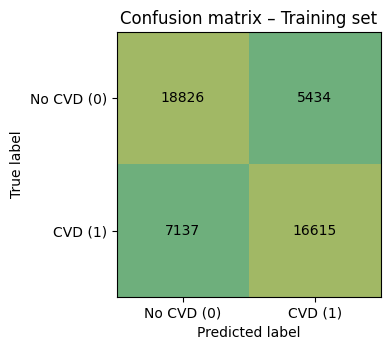

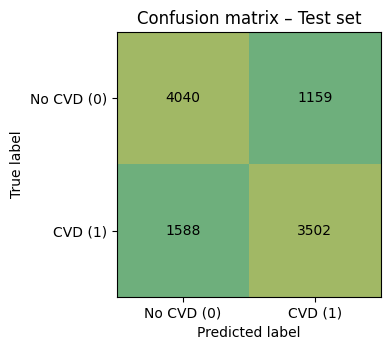

In [29]:
from matplotlib.colors import ListedColormap

# Custom 2-colour colormap for CM, if you like
cm_colors = ListedColormap(["#6EAF7C", "#A1B865"])

# TRAIN CM
cm_train = confusion_matrix(y_train, model.predict(X_train))
disp_train = ConfusionMatrixDisplay(cm_train, display_labels=["No CVD (0)", "CVD (1)"])

fig, ax = plt.subplots(figsize=(4, 4))
disp_train.plot(cmap=cm_colors, values_format="d", colorbar=False, ax=ax)
for text in disp_train.text_.ravel():
    text.set_color("black")
ax.set_title("Confusion matrix – Training set")
plt.tight_layout()
plt.show()

# TEST CM
cm_test = confusion_matrix(y_test, y_test_pred)
disp_test = ConfusionMatrixDisplay(cm_test, display_labels=["No CVD (0)", "CVD (1)"])

fig, ax = plt.subplots(figsize=(4, 4))
disp_test.plot(cmap=cm_colors, values_format="d", colorbar=False, ax=ax)
for text in disp_test.text_.ravel():
    text.set_color("black")
ax.set_title("Confusion matrix – Test set")
plt.tight_layout()
plt.show()

ROC curves

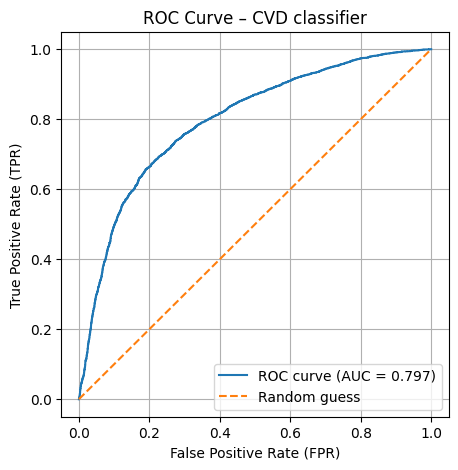

In [30]:
# ROC
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guess")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve – CVD classifier")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Precision–Recall curve

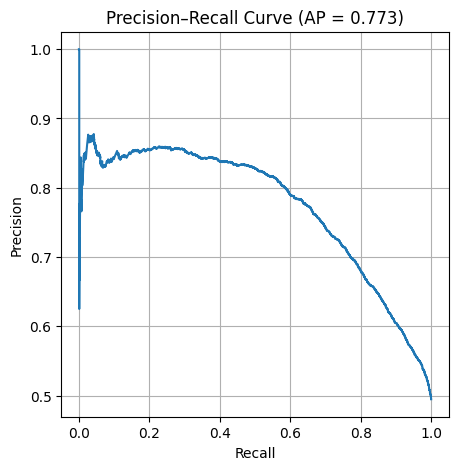

In [31]:
precision, recall, _ = precision_recall_curve(y_test, y_test_proba)
ap = average_precision_score(y_test, y_test_proba)

plt.figure(figsize=(5, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curve (AP = {ap:.3f})")
plt.grid(True)
plt.show()

11. Global explainability (Permutation importance + PDP)

Cholesterol    0.051832
Age            0.036363
PP             0.035066
SBP            0.018410
MAP            0.015817
DBP            0.015444
risk_count     0.006204
BMI            0.005778
active         0.004531
Glucose        0.002640
Gender         0.001453
alcohol        0.001021
smoking        0.000893
dtype: float64


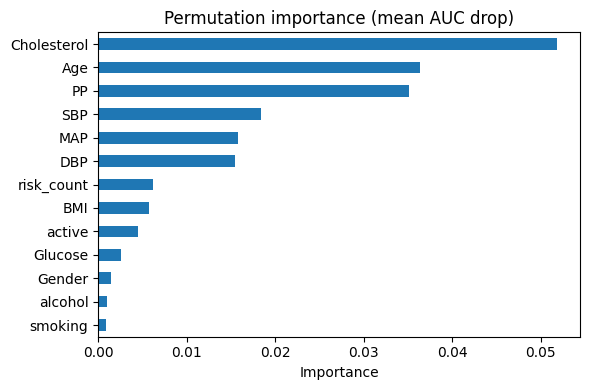

In [32]:
# Permutation importance
result_perm = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42
)

perm_importance = pd.Series(
    result_perm.importances_mean,
    index=feature_cols
).sort_values(ascending=False)

print(perm_importance)

plt.figure(figsize=(6, 4))
perm_importance.plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Permutation importance (mean AUC drop)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

Partial dependence plots for key features

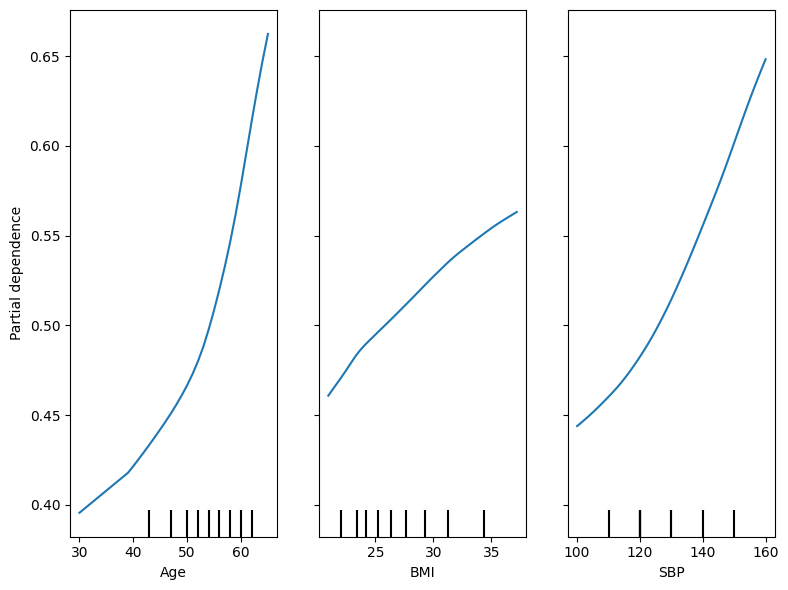

In [33]:
features_to_plot = ["Age", "BMI", "SBP"]

fig, ax = plt.subplots(figsize=(8, 6))
PartialDependenceDisplay.from_estimator(
    model,
    X_train,
    features_to_plot,
    kind="average",
    ax=ax
)
plt.tight_layout()
plt.show()

## 12. SHAP setup (global & local)

In [36]:
shap.initjs()

# background data for SHAP (from train set)
X_background = X_train.sample(300, random_state=42)

# Explainer for predict_proba
explainer = shap.Explainer(model.predict_proba, X_background)
class_idx = 1  # CVD = 1

# Compute SHAP on test data
X_explain = X_test.copy()
shap_values_all = explainer(X_explain)        # shape: (n_samples, 2, n_features)
shap_values_cvd = shap_values_all[..., 1]     # class 1 only

print("shap_values_cvd shape:", shap_values_cvd.values.shape)

PermutationExplainer explainer: 10290it [09:43, 17.46it/s]


shap_values_cvd shape: (10289, 13)


# SHAP global plots

Bar plot of mean |SHAP|

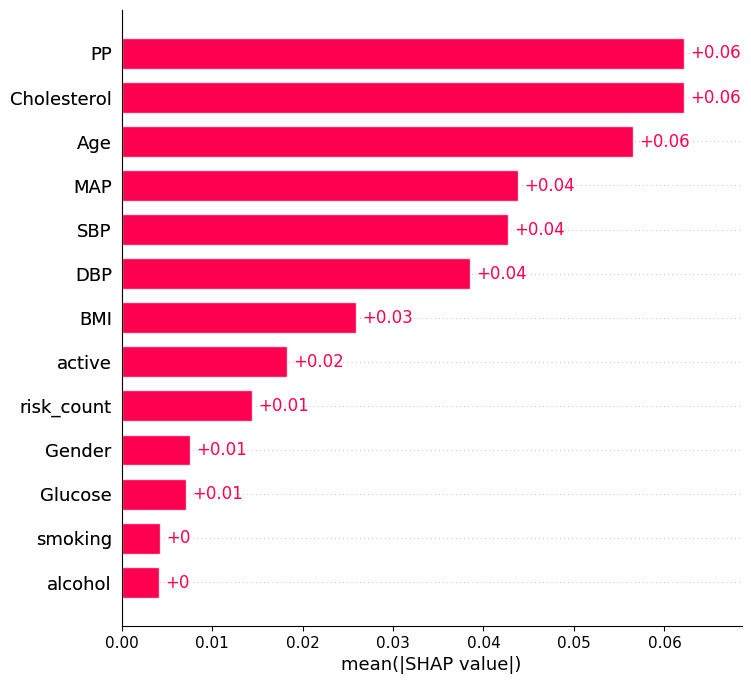

In [39]:
shap.plots.bar(shap_values_cvd, max_display=len(feature_cols))

Beeswarm plot

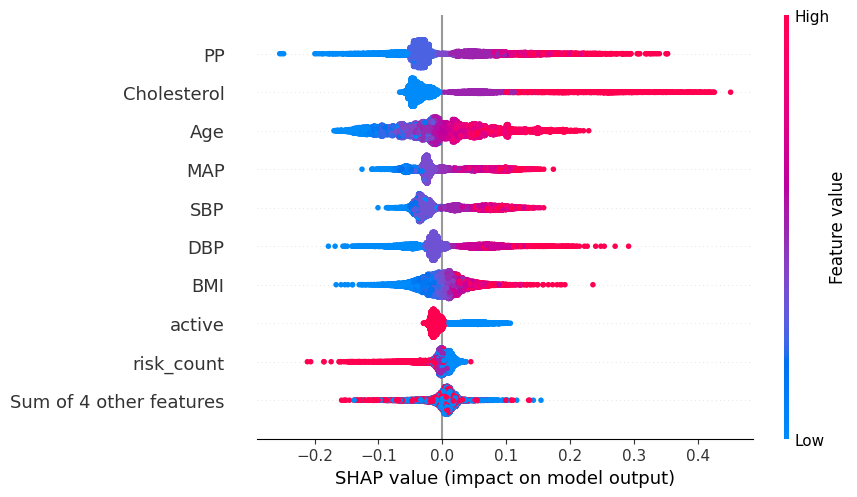

In [41]:
shap.plots.beeswarm(shap_values_cvd)

Dependence plot: BMI

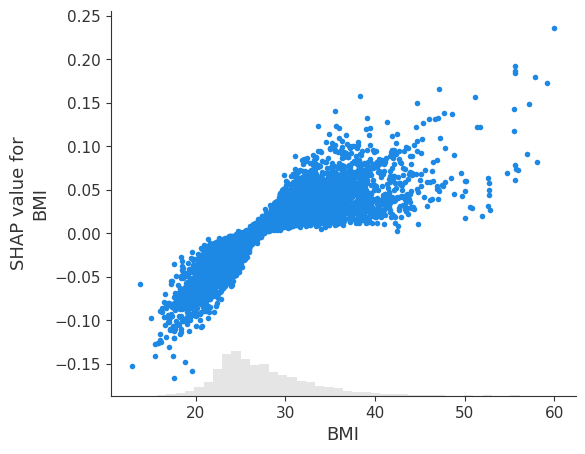

In [42]:
shap.plots.scatter(shap_values_cvd[:, "BMI"])               # SHAP vs BMI

Dependence plot: BMI(culoured)

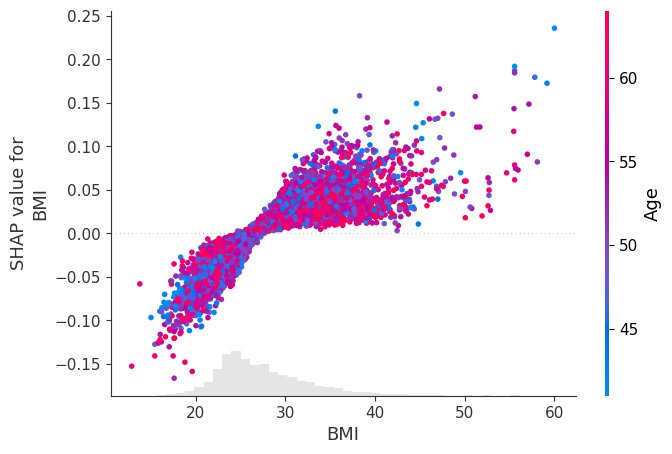

In [43]:
shap.plots.scatter(shap_values_cvd[:, "BMI"],
                   color=shap_values_cvd[:, "Age"])         # coloured by Age

13. SHAP local plots (one example patient)

Example test patient features:
Gender           1.000000
Age             60.000000
BMI             27.309968
SBP            150.000000
DBP            100.000000
Cholesterol      2.000000
Glucose          1.000000
smoking          1.000000
alcohol          0.000000
active           1.000000
PP              50.000000
MAP            116.666667
risk_count       2.000000
Name: 8156, dtype: float64


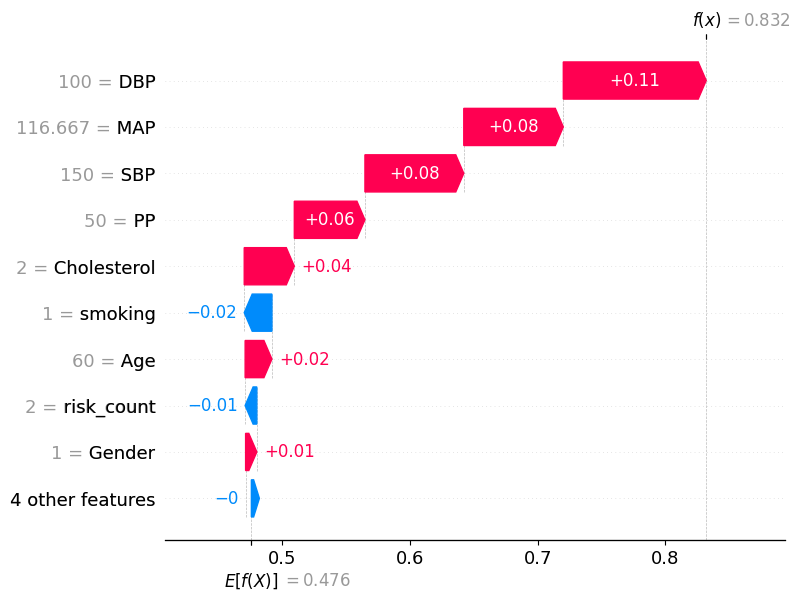

In [67]:
# choose an index from the test set
idx = 14

print("Example test patient features:")
print(X_test.iloc[idx])

shap.plots.waterfall(shap_values_cvd[idx], max_display=10)

Force plot (static)

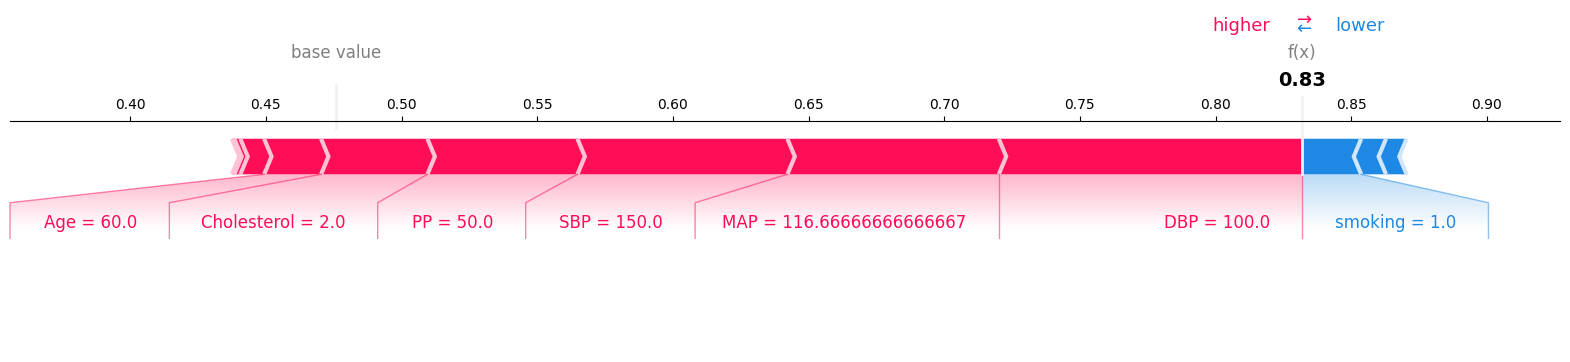

In [69]:
shap.plots.force(shap_values_cvd[idx], matplotlib=True)

14. LIME local explanation (same patient index)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


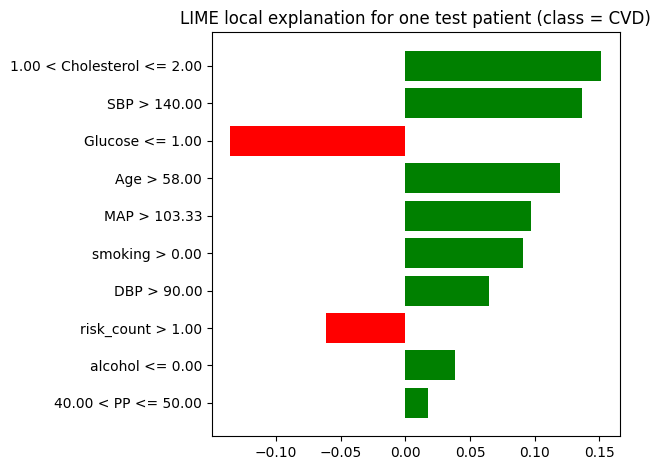

      Feature  Patient value         Feature (condition)  LIME weight
0        1.00            NaN  1.00 < Cholesterol <= 2.00     0.151673
1         SBP     150.000000                SBP > 140.00     0.136479
2     Glucose       1.000000             Glucose <= 1.00    -0.135245
3         Age      60.000000                 Age > 58.00     0.119980
4         MAP     116.666667                MAP > 103.33     0.097310
5     smoking       1.000000              smoking > 0.00     0.091158
6         DBP     100.000000                 DBP > 90.00     0.064592
7  risk_count       2.000000           risk_count > 1.00    -0.061467
8     alcohol       0.000000             alcohol <= 0.00     0.038467
9       40.00            NaN         40.00 < PP <= 50.00     0.017792


In [70]:
# Prepare NumPy arrays
X_train_np = X_train.values
X_test_np  = X_test.values

class_names = ["No CVD (0)", "CVD (1)"]

lime_explainer = LimeTabularExplainer(
    training_data = X_train_np,
    feature_names = feature_cols,
    class_names   = class_names,
    mode          = "classification",
    discretize_continuous = True
)

# Explain the same test instance as SHAP (idx)
x_instance = X_test_np[idx]

lime_exp = lime_explainer.explain_instance(
    data_row   = x_instance,
    predict_fn = model.predict_proba,
    num_features = 10,
    top_labels   = 2
)

fig = lime_exp.as_pyplot_figure(label=1)
plt.title("LIME local explanation for one test patient (class = CVD)")
plt.tight_layout()
plt.show()

# LIME table
lime_list = lime_exp.as_list(label=1)
lime_df = pd.DataFrame(lime_list, columns=["Feature (condition)", "LIME weight"])

patient_series = X_test.iloc[idx]
patient_dict   = patient_series.to_dict()

def extract_feature_name(lime_cond):
    return lime_cond.split()[0]

lime_df["Feature"] = lime_df["Feature (condition)"].apply(extract_feature_name)
lime_df["Patient value"] = lime_df["Feature"].map(patient_dict)

lime_df = lime_df[["Feature", "Patient value", "Feature (condition)", "LIME weight"]]
print(lime_df)

Clustering (K-Means)

/tmp/ipython-input-3945107150.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_clust['cluster'] = kmeans.fit_predict(X_clust)


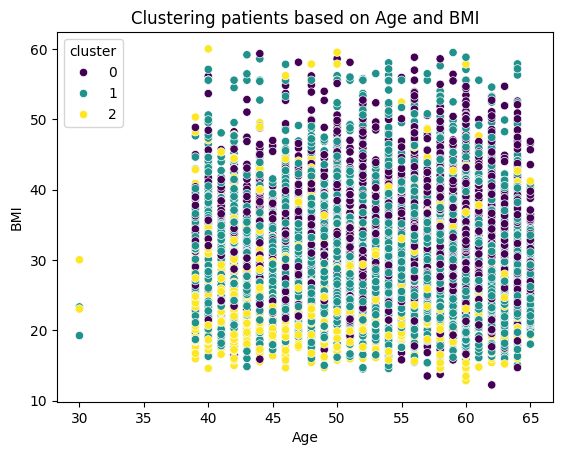

In [71]:
from sklearn.cluster import KMeans

# Select relevant features for clustering
X_clust = X[['Age', 'BMI', 'SBP', 'DBP']]

# Apply KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=42)
X_clust['cluster'] = kmeans.fit_predict(X_clust)

# Visualize clusters
import seaborn as sns
sns.scatterplot(x=X_clust['Age'], y=X_clust['BMI'], hue=X_clust['cluster'], palette='viridis')
plt.title("Clustering patients based on Age and BMI")
plt.show()


Simple “what-if” / counterfactual curve

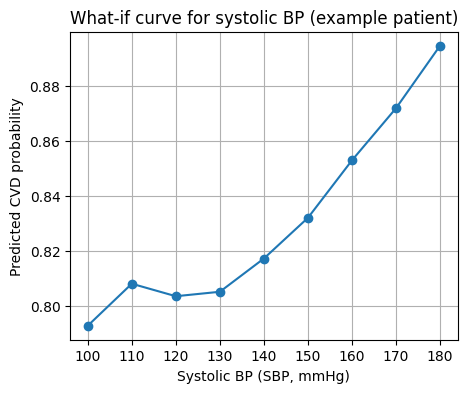

In [72]:
def what_if_curve(example_row, feature, value_grid):
    rows = []
    for v in value_grid:
        r = example_row.copy()
        r[feature] = v
        rows.append(r.iloc[0])
    X_grid = pd.DataFrame(rows)
    proba_grid = model.predict_proba(X_grid)[:, 1]
    return value_grid, proba_grid

# Example: what-if curve for systolic BP (SBP)
# Use the same example patient from SHAP/LIME explanation
example_patient_row = X_test.iloc[[idx]] # Use double brackets to keep it a DataFrame

bp_grid = np.arange(100, 181, 10)  # 100, 110, ..., 180
vals, probs = what_if_curve(example_patient_row, "SBP", bp_grid)

plt.figure(figsize=(5, 4))
plt.plot(vals, probs, marker="o")
plt.xlabel("Systolic BP (SBP, mmHg)")
plt.ylabel("Predicted CVD probability")
plt.title("What-if curve for systolic BP (example patient)")
plt.grid(True)
plt.show()

Counterfactual Explanations

In [73]:
import dice_ml
from dice_ml import Dice

# Combine X_train and y_train into a single DataFrame for DiCE
train_df_dice = X_train.copy()
train_df_dice['CVD'] = y_train

# Prepare DiCE model using RandomForest or Neural Network
dice_data = dice_ml.Data(dataframe=train_df_dice, continuous_features=feature_cols, outcome_name='CVD')

# Assuming 'rf_best' is your best Random Forest model from earlier cells
# If you want to use the MLP model, replace 'rf_best' with 'model'
model_dice = dice_ml.Model(model=rf_best, backend="sklearn")

# Create DiCE explainer
dice_explainer = Dice(dice_data, model_dice)

# Generate counterfactual for a test patient
# We need to make sure the input to generate_counterfactuals also has all feature_cols
# X_test.iloc[0:1] correctly provides features for one sample
counterfactual = dice_explainer.generate_counterfactuals(X_test.iloc[0:1], total_CFs=3, desired_class="opposite")
counterfactual.visualize_as_dataframe(show_only_changes=True)

100%|██████████| 1/1 [00:00<00:00,  1.01it/s]

Query instance (original outcome : 0)


,Gender,Age,BMI,SBP,DBP,Cholesterol,Glucose,smoking,alcohol,active,PP,MAP,risk_count,CVD
0,0,56,28.90625,110,70,2,1,0,0,1,40,83.333336,1,0



Diverse Counterfactual set (new outcome: 1)


,Gender,Age,BMI,SBP,DBP,Cholesterol,Glucose,smoking,alcohol,active,PP,MAP,risk_count,CVD
0,-,-,-,186.0,-,-,-,1.0,-,-,-,-,-,1.0
1,-,-,-,176.0,-,-,-,-,-,-,-,92.059002,-,1.0
2,-,-,-,-,-,3.0,-,-,-,-,-,-,2.0,1.0


15. Fairness metrics by gender

In [74]:
def group_metrics(group_value, group_name):
    mask = X_test["Gender"] == group_value

    y_true_g  = y_test[mask]
    y_pred_g  = y_test_pred[mask]
    y_proba_g = y_test_proba[mask]

    print(f"\n=== Metrics for {group_name} (Gender = {group_value}) ===")
    print("Samples in test set:", len(y_true_g))

    acc_g  = accuracy_score(y_true_g, y_pred_g)
    prec_g = precision_score(y_true_g, y_pred_g)
    rec_g  = recall_score(y_true_g, y_pred_g)

    tn, fp, fn, tp = confusion_matrix(y_true_g, y_pred_g).ravel()
    fpr_g = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    try:
        auc_g = roc_auc_score(y_true_g, y_proba_g)
    except ValueError:
        auc_g = float("nan")

    pos_rate = (y_pred_g == 1).mean()

    print(f"Accuracy      : {acc_g:.3f}")
    print(f"Precision     : {prec_g:.3f}")
    print(f"Recall (TPR)  : {rec_g:.3f}")
    print(f"False Pos Rate: {fpr_g:.3f}")
    print(f"Positive rate : {pos_rate:.3f}")
    print(f"AUC           : {auc_g:.3f}")

group_metrics(0, "Female")
group_metrics(1, "Male")


=== Metrics for Female (Gender = 0) ===
Samples in test set: 6710
Accuracy      : 0.737
Precision     : 0.747
Recall (TPR)  : 0.698
False Pos Rate: 0.226
Positive rate : 0.457
AUC           : 0.802

=== Metrics for Male (Gender = 1) ===
Samples in test set: 3579
Accuracy      : 0.726
Precision     : 0.759
Recall (TPR)  : 0.670
False Pos Rate: 0.216
Positive rate : 0.445
AUC           : 0.786
